<a href="https://colab.research.google.com/github/hyeseong-shin/NLP/blob/main/Lab1_Spam_Detection_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1. Build Your First NLP System: Rule-based Spam Detection

### 오늘의 목표
이번 실습에서는 **모델을 학습시키지 않습니다.**  
강의에서 배운 **Corpus → Tokenization → Rule-based Language Processing**을 실제 데이터에 적용해 하나의 NLP 시스템을 완성합니다.

**Raw Text → Corpus Exploration → Tokenization → Rule Design → Prediction → Evaluation → Error Analysis**

### Dataset
**SMS_Spam_Multilingual_Collection_Dataset**

주요 column:
- `labels`: 정답 label (`ham` / `spam`)
- `text`: 영어 원문 — **missing value 없음**
- `text_ko`: 한국어 번역문 — **56개 missing value**
- `text_hi`, `text_de`, `text_fr`, ...: 각 언어 번역문
- `Unnamed: 0`: CSV 저장 과정에서 생긴 index column

이번 Lab에서는 먼저 **영어 `text` 전체 5,572개**를 사용합니다.
한국어 challenge에서는 `text_ko`가 비어 있는 56개 행만 제외합니다.


## 0. Setup

필요한 라이브러리를 설치하고 불러옵니다.

In [ ]:
!pip -q install datasets huggingface_hub

In [ ]:
import re
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

random.seed(42)
np.random.seed(42)

## 1. Load the Corpus

### 방법 A — Hugging Face에서 직접 불러오기

접근 오류가 발생하면 아래 **방법 B**를 사용하세요.

In [ ]:
from datasets import load_dataset

DATASET_NAME = "KumarSahil299885/SMS_Spam_Multilingual_Collection_Dataset"

load_success = False
try:
  dataset = load_dataset(DATASET_NAME, split="train")
  df = dataset.to_pandas()
  load_success = True
  print("Loaded from Hugging Face:", df.shape)
except Exception as e:
  print("Hugging Face에서 데이터를 불러오지 못했습니다.")
  print("아래 방법 B를 사용하세요.")
  print(type(e).__name__, ":", str(e)[:300])

README.md:   0%|          | 0.00/1.32k [00:00<?, ?B/s]

data-augmented.csv: reconstructing file:   0%|          |  0.00B / 14.2MB            

data-augmented.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5572 [00:00<?, ? examples/s]

Loaded from Hugging Face: (5572, 23)


### 방법 B — CSV 파일 업로드

방법 A가 실패했을 때만 실행하세요.

In [ ]:
# from google.colab import files
# uploaded = files.upload()
# filename = next(iter(uploaded))
# df = pd.read_csv(filename)
# print("Loaded from CSV:", df.shape)

### 데이터 확인

우리가 다룰 **corpus**가 어떤 형태인지 확인합니다.

In [ ]:
df.head()

,Unnamed: 0,labels,text,text_hi,text_de,text_fr,text_es,text_zh,text_ar,text_bn,...,text_id,text_ur,text_pa,text_jv,text_tr,text_ko,text_mr,text_uk,text_sv,text_no
0,0,ham,"Go until jurong point, crazy.. Available only ...","Dakag बिंदु तक जाओ, पागल. केवल Bag Non महान वि...","Gehen Sie bis jurong Punkt, verrückt.. Verfügb...","Allez jusqu'à Jurong point, fou.. Disponible s...","Go until jurong point, crazy.. Available only ...","走到陪审点,疯狂.. 仅在 bugis n great world la e buffet....",الذهاب إلى نقطة الجورج، مجنون.. متوفر فقط في b...,যান যান যান যান যান যান যান যান যান যান যান যা...,...,"Pergi sampai jurong point, gila.. Tersedia han...",جاؤ جب تک جورج پوائنٹ، پاگل.. دستیاب صرف میں b...,ਗਾਹਕ 'ਤੇ ਗਾਹਕ 'ਤੇ ਗਾਹਕ 'ਤੇ ਗਾਹਕ 'ਤੇ ਗਾਹਕ 'ਤੇ ਗ...,"Ing titik jurong, crazy..Dapat ora ing bugis n...","Yürüyüş noktasına kadar gidin, çılgın.. Sadece...","조롱 포인트까지 가라, 미친.. 오직 bugis n great world la e ...","जॉर्ज बिंदुपर्यंत जा, पागल.. उपलब्ध फक्त bugis...","Ідіть до пункту присяги, божевільний.. Доступн...","Go till jurong point, crazy.. Tillgänglig bara...","Gå til jurong point, gal.. Tilgjengelig bare i..."
1,1,ham,Ok lar... Joking wif u oni...,ओके लामर.... if if uue पर.,Ok Lar... joking wif u oni...,J'ai fait une blague sur le wif u oni...,"Bueno, la broma, la broma...",哈哈哈哈哈哈哈哈哈哈哈哈哈哈哈哈哈,نعم نعم نعم نعم نعم نعم نعم...,হ্যাঁ হ্যাঁ হ্যাঁ হ্যাঁ হ্যাঁ হ্যাঁ হ্যাঁ হ্যা...,...,"Awalnya, ia bergurau dengan Wif U...",ہا ہا ہا ہا ہا ہا ہا ہا ہا ہا ہا ہا ہا ہا ہا,OK lar... Joking wif u oni...,Lan lan lan lan lan lan lan lan lan lan lan la...,Hayır hayır hayır hayır hayır hayır hayır,ᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏ,"शंका आहोत, शंका आहोत, शंका आहोत...","Звичайно ж, це жартує про те, що...",Ok lar... Joking wif u oni...,Ok lar... Joking wif u oni...
2,2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Fktatatat 21 मई को प्राप्त करने के लिए मुफ्त प...,Freier Eintritt in 2 a wkly comp zum Gewinn FA...,Entrée libre dans 2 a wkly comp pour gagner FA...,Ingreso gratuito en 2 a wkly comp para ganar F...,免费入场 2 a wkly comp 获胜 FA 杯决赛 tkts 2005年5月21日 文...,إدخال مجاني في 2 a wkly comp للفوز FA Cup fina...,বিনামূল্যে প্রবেশ 2 a wkly comp বিজয় FA কাপ ফ...,...,Free entry in 2 a wkly comp to win FA Cup fina...,مفت انٹرویو میں 2 a wkly comp جیتنے کے لئے FA ...,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp kanggo menang FA C...,Free entry in 2 a wkly comp to win FA Cup fina...,무료 입장 2 a wkly comp 승리 FA 컵 결승전 tkts 2005년 5월 ...,मुक्त प्रवेश 2 a wkly comp विजेता FA कप फाइनल ...,Безкоштовний вхід у 2 а wkly comp виграти ФА К...,Fri entré i 2 a wkly comp för att vinna FA Cup...,Free entry in 2 a wkly comp to win FA Cup fina...
3,3,ham,U dun say so early hor... U c already then say...,Uden इतना जल्दी कहते हैं... तो पहले से ही यूसी...,U dun sagen so früh... U c schon dann sagen...,U dun dit si tôt hor... U c déjà dire alors...,U dun dice tan temprano hor... U c ya entonces...,"U dun 说得这么早, U c 说得这么早......",وَقَالَ رَسُولُ اللَّهِ صَلَّى اللَّهُ عَلَيْه...,কখনো কখনো কখনো কখনো কখনো কখনো কখনো কখনো কখনো ক...,...,U dun berkata begitu awal hor... U c sudah kem...,U dun کہتے ہیں اتنا جلدی hor... U c پہلے ہی کہ...,U dun says so early hor... U c already then sa...,U dun saka begitu awal hor... U c uga saka...,U dun diyor o kadar erken hor... U c zaten o z...,ᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏ,त्याचबरोबरच त्याचबरोबरच त्याचबरोबरच त्याचबरोबर...,У дуні так рано говорити... У C вже тоді говор...,U dun säger så tidigt hor... U c säger redan d...,U dun sier så tidlig hor... U c sier allerede ...
4,4,ham,"Nah I don't think he goes to usf, he lives aro...","नहीं, मुझे नहीं लगता कि वह हमारे लिए चला जाता ...","Nein, ich glaube nicht, dass er zu unsf geht, ...","Non, je ne pense pas qu'il va à usf, il vit da...","No creo que vaya a la USF, pero vive aquí.","好吧,我不认为他去USF,他住在这里虽然",أنا لا أعتقد أنه يذهب إلى usf ، لكنه يعيش هنا ...,"আমি মনে করি তিনি ইউএসএফে যেতে পারবেন না, তিনি ...",...,"Saya tidak berpikir dia pergi ke usf, dia ting...",مجھے نہیں لگتا کہ وہ یو ا

In [ ]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

Shape: (5572, 23)

Columns: ['Unnamed: 0', 'labels', 'text', 'text_hi', 'text_de', 'text_fr', 'text_es', 'text_zh', 'text_ar', 'text_bn', 'text_ru', 'text_pt', 'text_ja', 'text_id', 'text_ur', 'text_pa', 'text_jv', 'text_tr', 'text_ko', 'text_mr', 'text_uk', 'text_sv', 'text_no']

Missing values:
Unnamed: 0     0
labels         0
text           0
text_hi        0
text_de        0
text_fr        0
text_es        0
text_zh       26
text_ar        1
text_bn        0
text_ru        0
text_pt        0
text_ja        0
text_id        0
text_ur        0
text_pa        0
text_jv        0
text_tr        0
text_ko       56
text_mr        0
text_uk        0
text_sv        0
text_no        0
dtype: int64


### 💭 Think about it

1. 이 데이터에서 **corpus**는 무엇이라고 볼 수 있을까요?
2. `text`, `label`, `language`은 각각 어떤 정보를 담고 있나요?
3. 규칙을 만들기 전에 데이터를 직접 살펴봐야 하는 이유는 무엇일까요?

## 2. Choose One Language

첫 번째 시스템은 **영어 메시지**를 대상으로 만듭니다.

먼저 `text` 컬럼의 실제 값을 확인합니다.

In [ ]:
df["text"].value_counts().head(30)

,count
text,
"Sorry, I'll call later",30
I cant pick the phone right now. Pls send a message,12
Ok...,10
"Say this slowly.? GOD,I LOVE YOU &amp; I NEED YOU,CLEAN MY HEART WITH YOUR BLOOD.Send this to Ten special people &amp; u c miracle tomorrow, do it,pls,pls do it...",4
Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaranteed £1000 cash or £5000 prize!,4
Ok.,4
Okie,4
Ok,4
"Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.",4


실습 시간을 일정하게 유지하기 위해 영어 데이터 중 일부만 사용합니다.

In [ ]:
# 1) 분석에 필요 없는 index column 제거
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# 2) label 확인
print("Label counts:")
print(df["labels"].value_counts())

# 3) 평가용 숫자 label 추가
label_map = {"ham": 0, "spam": 1}
df["label"] = (
    df["labels"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(label_map)
)

# 예상하지 못한 label이 있는지 확인
assert df["label"].notna().all(), "ham/spam 이외의 label이 있습니다."

# 4) 영어 text는 결측치가 없으므로 전체 5,572개 사용
lab_df = df[["text", "labels", "label"]].copy()

print("\nEnglish samples:", len(lab_df))
print("Missing English text:", lab_df["text"].isna().sum())

lab_df.head()


Label counts:
labels
ham     4825
spam     747
Name: count, dtype: int64

English samples: 5572
Missing English text: 0


,text,labels,label
0,"Go until jurong point, crazy.. Available only ...",ham,0
1,Ok lar... Joking wif u oni...,ham,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam,1
3,U dun say so early hor... U c already then say...,ham,0
4,"Nah I don't think he goes to usf, he lives aro...",ham,0


## 3. Explore the Corpus

### 3-1. Spam / Ham 예시 보기

In [ ]:
print("=== HAM ===")
for text in lab_df[lab_df["label"] == 0]["text"].head(5):
    print("-", text)

print("\n=== SPAM ===")
for text in lab_df[lab_df["label"] == 1]["text"].head(5):
    print("-", text)

=== HAM ===
- Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
- Ok lar... Joking wif u oni...
- U dun say so early hor... U c already then say...
- Nah I don't think he goes to usf, he lives around here though
- Even my brother is not like to speak with me. They treat me like aids patent.

=== SPAM ===
- Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
- FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
- WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
- Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030
- SIX c

### 3-2. Label distribution

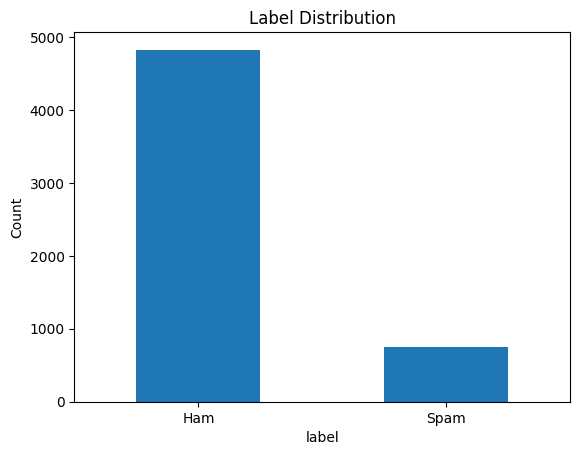

In [ ]:
lab_df["label"].value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["Ham", "Spam"], rotation=0)
plt.ylabel("Count")
plt.title("Label Distribution")
plt.show()

### 3-3. Message length

In [ ]:
lab_df["char_length"] = lab_df["text"].astype(str).str.len()
print(lab_df.groupby("label")["char_length"].describe()[["mean", "50%", "max"]])

             mean    50%    max
label                          
0       71.448705   52.0  910.0
1      137.989290  149.0  223.0


### 💭 Think about it

Spam과 Ham 사이에 눈에 띄는 차이가 있나요?

단어뿐 아니라 다음 특징도 생각해보세요.

- URL
- 숫자
- 돈 기호
- 대문자
- 느낌표
- 메시지 길이

# 4. Tokenization

먼저 Python의 가장 단순한 방법인 `.split()`을 사용합니다.  
`.split()`이란?  
- 문장(문자열)을 기본적으로 띄어쓰기(공백) 기준으로 싹둑 잘라주는 기능입니다.
- 예: "Click now".split() $\rightarrow$ ['Click', 'now']


In [ ]:
sample_text = "Congratulations! You've won $1,000!!! Click now."

simple_tokens = sample_text.split()
simple_tokens

['Congratulations!', "You've", 'won', '$1,000!!!', 'Click', 'now.']

### 💭 Think about it

`Congratulations!`, `$1,000!!!` 같은 결과는 우리가 원하는 token일까요?

### 4-1. 직접 간단한 tokenizer 만들기

정규표현식(regex)을 사용해 **영문 단어와 숫자**를 token으로 추출합니다.

**TODO:** `re.findall()`을 사용해 아래 함수를 완성하세요.  
`re.findall(규칙, 문장)`이란?
- 문장 전체를 훑으면서 **우리가 정학 규칙에 맞는 단어만 모두 찾아서 리스트로 뽑아주는 함수**입니다.
- `[a-z]+`: 알파벳 소문자(a부터 z)가 1개 이상 연속해서 이어진 부분(예: `congratulations`, `you`)
- `|`: 또는(OR)
- `[0-9]+`: 숫자(0부터 9)가 1개 이상 연속해서 이어진 부분(예: `1`, `000`)  
`.split()`과 `re.findall()` 결과 차이 비교:
- `.split()` 사용 시: `$1,000!!!`(특수문자까지 포함)
- `re.findall()` 사용 시: `['1', '000']` (기호는 빠지고 알파벳과 숫자만 추출)

In [ ]:
def simple_tokenize(text):
    text = text.lower()

    # TODO: 영문 단어(a-z) 또는 숫자(0-9)가 연속된 부분을 token으로 추출
    tokens = re.findall(r"[a-z]+|[0-9]+",text)

    return tokens

simple_tokenize(sample_text)

['congratulations', 'you', 've', 'won', '1', '000', 'click', 'now']

### 🧪 Try it

아래 문장들을 tokenization 해보세요.

In [ ]:
examples = [
    "FREE!!! Click https://example.com NOW!",
    "Call me at 010-1234-5678.",
    "오늘 저녁 7시에 만나자ㅎㅎ",
]

for text in examples:
    print(text)
    print(simple_tokenize(text))
    print()

FREE!!! Click https://example.com NOW!
['free', 'click', 'https', 'example', 'com', 'now']

Call me at 010-1234-5678.
['call', 'me', 'at', '010', '1234', '5678']

오늘 저녁 7시에 만나자ㅎㅎ
['7']



### 💭 Think about it

같은 tokenizer를 모든 언어에 사용할 수 있을까요?

> **Your answer:**
>

# 5. What Does Spam Look Like?

Spam과 Ham에서 자주 등장하는 token을 비교합니다.

In [ ]:
def get_token_counts(texts):
    counter = Counter()

    for text in texts:
        tokens = simple_tokenize(str(text))
        counter.update(tokens)

    return counter

spam_counts = get_token_counts(lab_df[lab_df["label"] == 1]["text"])
ham_counts = get_token_counts(lab_df[lab_df["label"] == 0]["text"])

print("Spam:", spam_counts.most_common(20))
print("\nHam:", ham_counts.most_common(20))

Spam: [('to', 688), ('a', 393), ('call', 367), ('2', 346), ('you', 299), ('your', 264), ('free', 228), ('1', 224), ('for', 204), ('now', 203), ('the', 203), ('or', 192), ('4', 190), ('u', 182), ('p', 180), ('txt', 170), ('150', 165), ('is', 157), ('on', 145), ('ur', 144)]

Ham: [('i', 2962), ('you', 1948), ('to', 1562), ('the', 1137), ('a', 1073), ('u', 1042), ('and', 858), ('in', 825), ('me', 777), ('my', 755), ('is', 739), ('it', 718), ('that', 561), ('of', 526), ('for', 507), ('s', 492), ('have', 443), ('can', 441), ('but', 441), ('so', 436)]


### 🧪 Try it — Find Spam Keywords

위 결과와 실제 문장을 보고 **spam을 나타낼 것 같은 단어를 5개 이상** 골라보세요.

In [ ]:
# TODO
SPAM_WORDS = [
    "free",
    "call",
    "claim",
    "offer",
    "reward",
    "winner",
    "prize"

]

SPAM_WORDS

['free', 'call', 'claim', 'offer', 'reward', 'winner', 'prize']

# 6. Extract Simple Features

Spam 판단에 사용할 특징(feature)을 만듭니다.

In [ ]:
def extract_features(text):
    text = str(text)
    tokens = simple_tokenize(text)

    features = {
        "spam_word_count": sum(token in SPAM_WORDS for token in tokens),

        # TODO 1: http:// 또는 https://가 포함되어 있으면 True
        "has_url": bool(re.search("https?://", text.lower())),

        # TODO 2: 느낌표(!)의 개수
        "num_exclamations": text.count("!"),

        # TODO 3: $, £, € 중 하나라도 포함되어 있으면 True
        "has_money_symbol": any(symbol in text for symbol in ["$","£","€"]),
    }

    return features

extract_features("FREE!!! You won $500. Click https://example.com")

{'spam_word_count': 1,
 'has_url': True,
 'num_exclamations': 3,
 'has_money_symbol': True}

# 7. Build a Rule-based Spam Detector

각 특징이 발견될 때마다 `spam_score`를 증가시키고,
일정 점수 이상이면 **Spam**, 아니면 **Ham**으로 판단합니다.

In [ ]:
def predict_spam(text):
    features = extract_features(text)

    spam_score = 0

    # spam keyword가 1개 이상 있으면 +1
    if features["spam_word_count"] >= 1:
        spam_score += 1

    # URL이 있으면 +1
    if features["has_url"]:
        spam_score += 1

    # 느낌표가 2개 이상이면 +1
    if features["num_exclamations"] >= 2:
        spam_score += 1

    # 돈 기호가 있으면 +1
    if features["has_money_symbol"]:
        spam_score += 1

    # score가 2 이상이면 spam(1), 아니면 ham(0)
    return 1 if spam_score >= 2 else 0

### 테스트

In [ ]:
test_messages = [
    "Congratulations!!! You won a FREE prize! Click https://fake.com",
    "Can you send me the lecture notes?",
    "FREE ticket available for tonight",
    "I found this free tutorial online.",
]

for msg in test_messages:
    print(msg)
    print("features:", extract_features(msg))
    print("prediction:", predict_spam(msg))
    print()

Congratulations!!! You won a FREE prize! Click https://fake.com
features: {'spam_word_count': 2, 'has_url': True, 'num_exclamations': 4, 'has_money_symbol': False}
prediction: 1

Can you send me the lecture notes?
features: {'spam_word_count': 0, 'has_url': False, 'num_exclamations': 0, 'has_money_symbol': False}
prediction: 0

FREE ticket available for tonight
features: {'spam_word_count': 1, 'has_url': False, 'num_exclamations': 0, 'has_money_symbol': False}
prediction: 0

I found this free tutorial online.
features: {'spam_word_count': 1, 'has_url': False, 'num_exclamations': 0, 'has_money_symbol': False}
prediction: 0



# 8. Evaluation

규칙을 사람이 직접 만들었더라도,
보지 않은 데이터에서 얼마나 잘 작동하는지 확인해야 합니다.

In [ ]:
train_df, test_df = train_test_split(
    lab_df,
    test_size=0.30,
    random_state=42,
    stratify=lab_df["label"]
)

print("Train:", train_df.shape)
print("Test :", test_df.shape)

Train: (3900, 4)
Test : (1672, 4)


In [ ]:
test_df = test_df.copy()
test_df["prediction"] = test_df["text"].apply(predict_spam)

accuracy = accuracy_score(test_df["label"], test_df["prediction"])
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9145


### Confusion Matrix

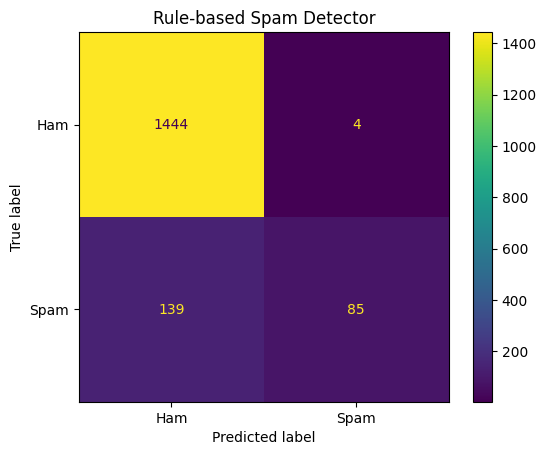

In [ ]:
cm = confusion_matrix(test_df["label"], test_df["prediction"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)
disp.plot()
plt.title("Rule-based Spam Detector")
plt.show()

### 💭 Think about it

- Spam인데 Ham으로 예측한 경우
- Ham인데 Spam으로 예측한 경우

어느 오류가 더 많나요?

> **Your answer:**
>

# 9. Error Analysis

점수만 보지 말고 실제 오류를 확인합니다.

In [ ]:
errors = test_df[test_df["label"] != test_df["prediction"]]

print("Number of errors:", len(errors))
errors[["text", "label", "prediction"]].head(10)

Number of errors: 143


,text,label,prediction
4647,We tried to contact you re your reply to our o...,1,0
4169,Congrats! Nokia 3650 video camera phone is you...,1,0
2699,FROM 88066 LOST £12 HELP,1,0
129,HEY GIRL. HOW R U? HOPE U R WELL ME AN DEL R B...,0,1
2619,Hey pple...$700 or $900 for 5 nights...Excelle...,0,1
5466,http//tms. widelive.com/index. wml?id=820554ad...,1,0
1263,"Hungry gay guys feeling hungry and up 4 it, no...",1,0
4903,* FREE* POLYPHONIC RINGTONE Text SUPER to 8713...,1,0
5098,TheMob>Hit the link to get a premium Pink Pant...,1,0
4571,Wanna have a laugh? Try CHIT-CHAT on your mobi...,1,0


### 🧪 Try it — Improve Your Rules

오류 사례를 보고 다음 중 하나 이상을 수정해보세요.

- `SPAM_WORDS`
- feature
- 각 rule의 조건
- spam 판정 threshold

수정 후 Evaluation 셀을 다시 실행하여 성능 변화를 확인하세요.

> 규칙을 추가한다고 항상 성능이 좋아지는 것은 아닙니다.

# 10. Challenge — Break the Classifier

### Challenge A
사람이 보기에는 **Spam**인데 detector는 **Ham**으로 예측하는 문장을 만들어보세요.

### Challenge B
사람이 보기에는 **Ham**인데 detector는 **Spam**으로 예측하는 문장을 만들어보세요.

In [ ]:
spam_but_predicted_ham = "TODO"
ham_but_predicted_spam = "TODO"

print("A:", predict_spam(spam_but_predicted_ham))
print("B:", predict_spam(ham_but_predicted_spam))

### 💭 Think about it

왜 이런 오류가 발생했을까요?

> **Your answer:**
>

# 11. Optional Challenge — Does It Work in Korean?

영어 데이터를 보고 만든 규칙을 한국어 데이터에 그대로 적용해봅니다.

In [ ]:
# text_ko가 존재하는 행만 사용
ko_df = (
    df.dropna(subset=["text_ko"])
      [["text_ko", "labels", "label"]]
      .copy()
)

# 기존 classifier 함수가 `text`를 입력으로 사용하므로 column 이름을 통일
ko_df = ko_df.rename(columns={"text_ko": "text"})

print("Total rows        :", len(df))
print("Missing text_ko   :", df["text_ko"].isna().sum())
print("Korean samples    :", len(ko_df))

ko_df.head(10)


In [ ]:
ko_df["prediction"] = ko_df["text"].apply(predict_spam)

ko_accuracy = accuracy_score(
    ko_df["label"],
    ko_df["prediction"]
)

print(f"English Accuracy ({len(test_df)} test samples): {accuracy:.4f}")
print(f"Korean Accuracy  ({len(ko_df)} samples): {ko_accuracy:.4f}")


### 🚀 Challenge

1. 한국어 spam 메시지를 확인합니다.
2. 한국어에 맞는 keyword/rule을 3개 이상 추가합니다.
3. 다시 평가합니다.

### 💭 Think about it

영어에서 만든 규칙이 한국어에서 잘 작동하지 않는다면 왜일까요?

- 언어 차이?
- tokenization?
- 데이터 품질?
- rule coverage?

하나의 원인으로 단정하지 말고 **실제 데이터를 근거로** 생각해보세요.

# 12. Wrap-up

오늘 만든 시스템:

**Corpus → Tokenization → Feature Extraction → Rules → Prediction → Evaluation → Error Analysis**

마지막 질문:

> **새로운 spam 표현이 계속 등장한다면 사람이 매번 새로운 규칙을 만들어야 할까요?**

다음 단계에서는 사람이 모든 규칙을 직접 작성하는 대신,
**데이터로부터 패턴을 학습하는 방법**을 살펴봅니다.